# Mission Eagle-1 — Pilote automatique par apprentissage par renforcement

Objectif de la mission : entraîner un agent capable de poser le module Eagle-1 avec une récompense moyenne **≥ 200 sur 100 épisodes**.

## Étape 1 — Explorer l'environnement et établir une performance de référence


### 1.1 — Exploration de l'environnement

> Le brief cite `LunarLander-v2`, mais cette version a été retirée de Gymnasium 1.0. On utilise `LunarLander-v3`, qui est le même problème avec des bugs corrigés.

In [1]:
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
from stable_baselines3 import DQN
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor

ENV_ID = "LunarLander-v3"
SEED = 0          # graine de l'entraînement
SEED_EVAL = 1000  # graine de l'évaluation : des situations de départ jamais vues à l'entraînement

env = gym.make(ENV_ID)

print("Espace d'observation :", env.observation_space)
print("Espace d'action      :", env.action_space)
print("Durée max d'un épisode :", env.spec.max_episode_steps, "pas")
print("Seuil de réussite      :", env.spec.reward_threshold)

Espace d'observation : Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espace d'action      : Discrete(4)
Durée max d'un épisode : 1000 pas
Seuil de réussite      : 200


#### Ce que l'agent voit : 8 valeurs continues

| Indice | Variable | Signification |
|---|---|---|
| 0 | `x` | position horizontale (0 = centre de la zone cible) |
| 1 | `y` | altitude (0 = niveau de la zone cible) |
| 2 | `vx` | vitesse horizontale |
| 3 | `vy` | vitesse verticale (négative = le module descend) |
| 4 | `angle` | inclinaison du module, en radians (0 = droit) |
| 5 | `v_angle` | vitesse de rotation |
| 6 | `pied_gauche` | 1 si le pied gauche touche le sol, sinon 0 |
| 7 | `pied_droit` | 1 si le pied droit touche le sol, sinon 0 |

#### Ce que l'agent peut faire : 4 actions discrètes

| Action | Effet |
|---|---|
| 0 | ne rien faire |
| 1 | allumer le moteur d'orientation gauche |
| 2 | allumer le moteur principal (pousse vers le haut) |
| 3 | allumer le moteur d'orientation droit |

L'espace d'action est **discret** : on choisit donc **DQN**, comme le recommande l'énoncé.

In [2]:
NOMS_OBSERVATIONS = ["x", "y", "vx", "vy", "angle", "v_angle", "pied_gauche", "pied_droit"]
NOMS_ACTIONS = ["rien", "moteur gauche", "moteur principal", "moteur droit"]

obs, info = env.reset(seed=SEED)

print("Observation au départ d'un épisode :")
for nom, valeur, bas, haut in zip(NOMS_OBSERVATIONS, obs, env.observation_space.low, env.observation_space.high):
    print(f"  {nom:<12} = {valeur:+.3f}   (bornes : {bas:+.2f} à {haut:+.2f})")

Observation au départ d'un épisode :
  x            = +0.006   (bornes : -2.50 à +2.50)
  y            = +1.399   (bornes : -2.50 à +2.50)
  vx           = +0.578   (bornes : -10.00 à +10.00)
  vy           = -0.528   (bornes : -10.00 à +10.00)
  angle        = -0.007   (bornes : -6.28 à +6.28)
  v_angle      = -0.131   (bornes : -10.00 à +10.00)
  pied_gauche  = +0.000   (bornes : -0.00 à +1.00)
  pied_droit   = +0.000   (bornes : -0.00 à +1.00)


Le module part toujours du haut de l'écran, au centre (`x ≈ 0`, `y ≈ 1.4`), mais avec une **vitesse initiale aléatoire**. C'est ce qui rend chaque épisode différent.

#### La récompense

- Elle augmente quand le module se rapproche de la zone cible, ralentit et se redresse.
- **+10** par pied posé au sol.
- **−0,3** par pas avec le moteur principal allumé, **−0,03** par pas avec un moteur latéral : c'est le coût du carburant.
- **+100** si le module se pose et s'immobilise, **−100** s'il s'écrase.

Un épisode s'arrête si le module s'écrase, sort de l'écran, s'immobilise au sol, ou au bout de 1000 pas.

In [3]:
# Effet d'une action : on allume le moteur principal pendant 5 pas
print(f"{'pas':>3} | {'action':<16} | {'vy':>7} | {'récompense':>10}")
for pas in range(1, 6):
    obs, reward, terminated, truncated, info = env.step(2)
    print(f"{pas:>3} | {NOMS_ACTIONS[2]:<16} | {obs[3]:+.3f} | {reward:>+10.2f}")

pas | action           |      vy | récompense
  1 | moteur principal | -0.490 |      +2.57
  2 | moteur principal | -0.480 |      +0.95
  3 | moteur principal | -0.482 |      +0.88
  4 | moteur principal | -0.454 |      +1.22
  5 | moteur principal | -0.429 |      +1.60


### 1.2 — Agent aléatoire : le plancher

Avant d'entraîner quoi que ce soit, on mesure le score d'un agent qui choisit ses actions au hasard. Ce chiffre sert de plancher : un agent entraîné doit faire mieux.

In [4]:
def jouer_aleatoire(env, n_episodes, seed):
    """Joue n_episodes avec des actions au hasard et renvoie la récompense et la durée de chaque épisode."""
    env.action_space.seed(seed)
    recompenses, durees = [], []

    for episode in range(n_episodes):
        obs, info = env.reset(seed=seed + episode)
        total, n_pas = 0.0, 0
        terminated = truncated = False

        while not (terminated or truncated):
            obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
            total += reward
            n_pas += 1

        recompenses.append(total)
        durees.append(n_pas)

    return np.array(recompenses), np.array(durees)


N_EVAL_EPISODES = 50

rec_aleatoire, durees_aleatoire = jouer_aleatoire(env, N_EVAL_EPISODES, SEED_EVAL)

print(f"Agent aléatoire sur {N_EVAL_EPISODES} épisodes")
print(f"  Récompense moyenne : {rec_aleatoire.mean():.1f} +/- {rec_aleatoire.std():.1f}")
print(f"  Min / max          : {rec_aleatoire.min():.1f} / {rec_aleatoire.max():.1f}")
print(f"  Durée moyenne      : {durees_aleatoire.mean():.0f} pas")

Agent aléatoire sur 50 épisodes
  Récompense moyenne : -210.6 +/- 104.3
  Min / max          : -459.1 / -77.6
  Durée moyenne      : 97 pas


### 1.3 — Premier agent : DQN avec les paramètres par défaut

On ne règle aucun hyperparamètre : on prend le DQN de Stable-Baselines3 tel quel. `Monitor` enregistre la récompense de chaque épisode, ce qui permet de tracer la courbe d'apprentissage.

In [5]:
TOTAL_TIMESTEPS = 100_000  # nombre de pas (appels à env.step), pas d'épisodes

train_env = Monitor(gym.make(ENV_ID))

model = DQN("MlpPolicy", train_env, verbose=0, tensorboard_log="./logs/", seed=SEED)

print("Paramètres par défaut du DQN :")
print("  learning_rate          :", model.learning_rate)
print("  gamma                  :", model.gamma)
print("  buffer_size            :", model.buffer_size)
print("  batch_size             :", model.batch_size)
print("  learning_starts        :", model.learning_starts)
print("  train_freq             :", model.train_freq.frequency, "pas")
print("  target_update_interval :", model.target_update_interval)
print("  exploration            : epsilon de", model.exploration_initial_eps, "à", model.exploration_final_eps,
      "sur les premiers", f"{model.exploration_fraction:.0%}", "des pas")

Paramètres par défaut du DQN :
  learning_rate          : 0.0001
  gamma                  : 0.99
  buffer_size            : 1000000
  batch_size             : 32
  learning_starts        : 100
  train_freq             : 4 pas
  target_update_interval : 10000
  exploration            : epsilon de 1.0 à 0.05 sur les premiers 10% des pas


In [6]:
model.learn(total_timesteps=TOTAL_TIMESTEPS, tb_log_name="dqn_defaut")

rec_entrainement = np.array(train_env.get_episode_rewards())
print(f"Entraînement terminé : {TOTAL_TIMESTEPS} pas, {len(rec_entrainement)} épisodes joués")
print(f"Récompense moyenne des 50 derniers épisodes d'entraînement : {rec_entrainement[-50:].mean():.1f}")

Entraînement terminé : 100000 pas, 247 épisodes joués
Récompense moyenne des 50 derniers épisodes d'entraînement : -25.5


#### Courbe d'apprentissage

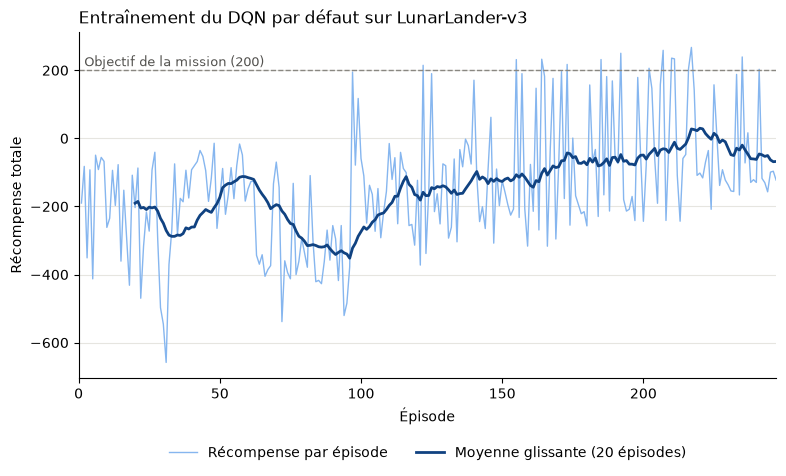

In [7]:
FENETRE = 20
episodes = np.arange(1, len(rec_entrainement) + 1)
moyenne_glissante = np.convolve(rec_entrainement, np.ones(FENETRE) / FENETRE, mode="valid")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(episodes, rec_entrainement, color="#86b6ef", linewidth=1, label="Récompense par épisode")
ax.plot(episodes[FENETRE - 1:], moyenne_glissante, color="#104281", linewidth=2,
        label=f"Moyenne glissante ({FENETRE} épisodes)")
ax.axhline(200, color="#898781", linewidth=1, linestyle="--")
ax.text(2, 212, "Objectif de la mission (200)", color="#52514e", fontsize=9)

ax.set_title(f"Entraînement du DQN par défaut sur {ENV_ID}", loc="left")
ax.set_xlabel("Épisode")
ax.set_ylabel("Récompense totale")
ax.set_xlim(0, len(rec_entrainement))
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
plt.show()

### 1.4 — Évaluation de référence

On évalue sur un environnement **séparé**, avec une autre graine que l'entraînement, sur 50 épisodes. Pendant l'évaluation l'agent n'explore plus (`deterministic=True`) : il joue toujours l'action qu'il juge la meilleure.

In [8]:
eval_env = Monitor(gym.make(ENV_ID))
eval_env.reset(seed=SEED_EVAL)

rec_dqn, durees_dqn = evaluate_policy(
    model, eval_env, n_eval_episodes=N_EVAL_EPISODES, deterministic=True, return_episode_rewards=True
)
rec_dqn, durees_dqn = np.array(rec_dqn), np.array(durees_dqn)

print(f"DQN par défaut sur {N_EVAL_EPISODES} épisodes")
print(f"  Récompense moyenne : {rec_dqn.mean():.1f} +/- {rec_dqn.std():.1f}")
print(f"  Min / max          : {rec_dqn.min():.1f} / {rec_dqn.max():.1f}")
print(f"  Durée moyenne      : {durees_dqn.mean():.0f} pas")
print(f"  Épisodes >= 200    : {(rec_dqn >= 200).sum()} / {N_EVAL_EPISODES}")

DQN par défaut sur 50 épisodes
  Récompense moyenne : -112.9 +/- 74.5
  Min / max          : -187.4 / 242.1
  Durée moyenne      : 970 pas
  Épisodes >= 200    : 1 / 50


In [9]:
print(f"{'Agent':<22} | {'Récompense moyenne':>18} | {'Écart-type':>10} | {'Épisodes >= 200':>15}")
print("-" * 75)
for nom, rec in [("Aléatoire", rec_aleatoire), ("DQN par défaut", rec_dqn)]:
    print(f"{nom:<22} | {rec.mean():>18.1f} | {rec.std():>10.1f} | {(rec >= 200).sum():>12} / {len(rec)}")
print(f"{'Objectif de la mission':<22} | {200:>18.1f} |")

Agent                  | Récompense moyenne | Écart-type | Épisodes >= 200
---------------------------------------------------------------------------
Aléatoire              |             -210.6 |      104.3 |            0 / 50
DQN par défaut         |             -112.9 |       74.5 |            1 / 50
Objectif de la mission |              200.0 |


In [10]:
import os

os.makedirs("models", exist_ok=True)
model.save("models/dqn_defaut")  # crée models/dqn_defaut.zip

env.close()
train_env.close()
eval_env.close()

### 1.5 — Analyse

| Agent | Récompense moyenne (50 épisodes) | Écart-type | Durée moyenne | Épisodes ≥ 200 |
|---|---|---|---|---|
| Aléatoire | −210,6 | 104,3 | 97 pas | 0 / 50 |
| **DQN par défaut (100 000 pas)** | **−112,9** | 74,5 | 970 pas | 1 / 50 |
| Objectif de la mission | ≥ 200 | | | |

**Performance de référence : −112,9.** L'agent a appris quelque chose (il gagne environ 100 points sur le hasard), mais il est très loin de l'objectif.

**Ce que l'agent a appris.** L'agent aléatoire s'écrase en 97 pas en moyenne. Le DQN, lui, tient 970 pas : presque tous ses épisodes vont jusqu'à la limite de 1000 pas. Il a donc appris à **ne plus s'écraser**, en restant en vol stationnaire, mais pas à **se poser**. Il évite le −100 du crash sans jamais toucher le +100 de l'atterrissage, et il brûle du carburant pendant tout l'épisode, ce qui explique son score négatif.

**Ce que montre la courbe.** La moyenne glissante monte d'environ −300 à −50 pendant l'entraînement et monte encore à la fin : l'agent n'a pas fini d'apprendre. Quelques épisodes dépassent déjà 200, donc un bon atterrissage est à sa portée, mais pas de façon régulière.

**Écart entre entraînement et évaluation.** Les 50 derniers épisodes d'entraînement donnent −25,5 en moyenne, contre −112,9 à l'évaluation. Ce ne sont pas les mêmes conditions : à l'entraînement l'agent joue encore 5 % d'actions au hasard et ses poids changent d'un épisode à l'autre. L'écart-type de 74,5 montre aussi que le résultat varie beaucoup d'un épisode à l'autre.

**Pistes pour l'étape suivante.**
- Entraîner plus longtemps : 100 000 pas ne représentent que 247 épisodes.
- Régler les hyperparamètres par défaut, peu adaptés ici : `learning_rate` de 0,0001 (apprentissage lent), `target_update_interval` de 10 000 pas (le réseau cible n'a été mis à jour que 10 fois), exploration réduite à 5 % dès les premiers 10 % de l'entraînement.
- Comparer avec PPO.

## Étape 2 — Améliorer l'agent jusqu'à une moyenne stable au-dessus de 200

### 2.1 — Méthode

**Un seul paramètre à la fois.** Chaque expérience part de la meilleure configuration trouvée avant elle et change **un seul** paramètre. Si la moyenne d'évaluation progresse, on garde le changement ; sinon on l'annule. On isole ainsi l'effet de chaque paramètre tout en avançant vers 200.

**Même budget pour toute une série.** Toutes les expériences DQN ont 300 000 pas et toutes les expériences PPO 1 000 000 de pas. Sinon on ne saurait pas si un meilleur score vient du paramètre ou du temps d'entraînement. PPO reçoit plus de pas car il réutilise moins bien son expérience que DQN (il jette ses données après chaque mise à jour, DQN les garde dans sa mémoire de replay).

**Trois jeux de situations séparés** (graines), pour ne jamais noter l'agent sur des épisodes qu'il a servi à choisir :

| Graines | Rôle |
|---|---|
| 500 et suivantes | pendant l'entraînement, un `EvalCallback` joue 20 épisodes tous les 25 000 pas et sauvegarde le meilleur modèle |
| 1000 à 1099 | on évalue ce meilleur modèle sur 100 épisodes pour comparer les expériences entre elles |
| 5000 à 5099 | évaluation finale du modèle retenu, utilisée **une seule fois**, à la fin |

**Le code est dans deux fichiers à côté du notebook :**
- [entrainement.py](entrainement.py) : `lancer_experience()` entraîne, sauvegarde et évalue une expérience ; `lancer_serie()` enchaîne une série en appliquant la règle « un paramètre à la fois ».
- [experiences.py](experiences.py) : le plan des expériences.

Chaque résultat est enregistré dans `resultats/<nom>.json` et chaque modèle dans `models/<nom>/`. Une expérience déjà faite n'est pas réentraînée : le notebook relit son résultat. Les entraînements ont été lancés en ligne de commande (`python experiences.py DQN` et `python experiences.py PPO`, en parallèle), puis ce notebook a relu leurs résultats.

**TensorBoard.** Toutes les courbes d'entraînement sont dans `Astro/logs/`. Pour les superposer, lancer depuis la racine du projet (`Train_RL-`) le TensorBoard du `.venv` d'Astro :
```
Astro\.venv\Scripts\tensorboard --logdir Astro\logs
```
puis ouvrir http://localhost:6006. Le notebook trace aussi les courbes d'évaluation ci-dessous.

In [11]:
import shutil
from pathlib import Path

from entrainement import (SEED_TEST, charger_resultats, evaluer, lancer_experience, lancer_serie, resume)
from experiences import BUDGET_DQN, BUDGET_PPO, SERIE_DQN, SERIE_PPO

In [12]:
def tableau(journal):
    """Affiche le journal d'une série : ce qui a été changé, le résultat et la décision."""
    print(f"{'Expérience':<18} | {'Changement':<28} | {'Moyenne':>7} | {'Écart-type':>10} | "
          f"{'Réussite':>8} | {'Durée':>6} | Décision")
    print("-" * 107)
    for i, ligne in enumerate(journal):
        # policy_kwargs={'net_arch': [...]} est affiché net_arch=[...] pour tenir dans la colonne
        changement = dict(ligne["changement"])
        changement.update(changement.pop("policy_kwargs", {}))
        changement = ", ".join(f"{k}={v}" for k, v in changement.items()) or "aucun"
        decision = "référence" if i == 0 else ("gardé" if ligne["garde"] else "annulé")
        print(f"{ligne['nom']:<18} | {changement:<28} | {ligne['moyenne']:>7.1f} | {ligne['ecart_type']:>10.1f} | "
              f"{ligne['taux_reussite']:>8.0%} | {ligne['duree_moyenne']:>6.0f} | {decision}")


# Couleurs : une par expérience, toujours dans le même ordre
COULEURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]


def tracer_courbes(journal, titre):
    """Courbe de validation de chaque expérience : score moyen des 20 épisodes de l'EvalCallback."""
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for couleur, ligne in zip(COULEURS, journal):
        evaluations = np.load(Path("models") / ligne["nom"] / "evaluations.npz")
        style = "-" if ligne["garde"] else ":"
        ax.plot(evaluations["timesteps"], evaluations["results"].mean(axis=1), style,
                color=couleur, linewidth=2, label=ligne["nom"] + ("" if ligne["garde"] else " (annulé)"))

    ax.axhline(200, color="#898781", linewidth=1, linestyle="--")
    ax.text(0, 215, "Objectif (200)", color="#52514e", fontsize=9)
    # Quelques évaluations très basses (crashs en début d'entraînement) écraseraient les autres courbes :
    # on coupe l'axe à -400 pour lire ce qui se passe autour de 200
    ax.set_ylim(-400, 330)
    ax.set_title(titre + " (axe coupé à −400)", loc="left")
    ax.set_xlabel("Pas d'entraînement (milliers)")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x / 1000:.0f}"))
    ax.set_ylabel("Récompense moyenne (20 épisodes)")
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False, fontsize=9)
    plt.show()


def tracer_barres(journal, titre):
    """Moyenne +/- écart-type sur 100 épisodes de validation, pour chaque expérience."""
    noms = [ligne["nom"] for ligne in journal]
    moyennes = [ligne["moyenne"] for ligne in journal]
    ecarts = [ligne["ecart_type"] for ligne in journal]
    couleurs = ["#2a78d6" if ligne["garde"] else "#c3c2b7" for ligne in journal]

    fig, ax = plt.subplots(figsize=(9, 4.2))
    ax.bar(noms, moyennes, yerr=ecarts, color=couleurs, width=0.6, capsize=4, error_kw={"ecolor": "#52514e"})
    for i, m in enumerate(moyennes):
        ax.text(i, m + (8 if m >= 0 else -8), f"{m:.0f}", ha="center", va="bottom" if m >= 0 else "top",
                fontsize=9, color="#0b0b0b")
    ax.axhline(200, color="#898781", linewidth=1, linestyle="--")
    ax.axhline(0, color="#c3c2b7", linewidth=1)
    ax.set_title(titre, loc="left")
    ax.set_ylabel("Récompense (100 épisodes)")
    ax.tick_params(axis="x", labelrotation=20)
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#2a78d6"), plt.Rectangle((0, 0), 1, 1, color="#c3c2b7")],
              labels=["Changement gardé", "Changement annulé"], loc="upper center",
              bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False)
    plt.show()

### 2.2 — Série DQN (300 000 pas par expérience)

L'étape 1 a montré un agent qui reste en vol stationnaire sans se poser, avec une courbe encore en hausse. Les expériences s'attaquent d'abord aux réglages par défaut mis en cause :

| Expérience | Paramètre changé | Défaut → essai | Pourquoi |
|---|---|---|---|
| D0 | aucun | — | Référence : mesurer l'effet du seul budget (300 000 pas au lieu de 100 000) |
| D1 | `target_update_interval` | 10 000 → 250 | Le réseau cible fournit les « bonnes réponses » de l'apprentissage. Recopié tous les 10 000 pas, il est trop souvent en retard sur ce que l'agent sait |
| D2 | `learning_rate` | 1e-4 → 6e-4 | Des corrections de poids plus grandes : un apprentissage plus rapide |
| D3 | `buffer_size` | 1 000 000 → 50 000 | Une mémoire plus petite oublie plus vite les transitions jouées par l'agent débutant |
| D4 | `batch_size` | 32 → 128 | Chaque mise à jour moyenne sur plus de transitions : elle est moins bruitée |
| D5 | `net_arch` | [64, 64] → [256, 256] | Un réseau plus grand peut représenter une conduite plus fine |
| D6 | `gamma` | 0,99 → 0,999 | L'agent accorde plus de poids aux récompenses lointaines, comme le +100 de l'atterrissage |

In [13]:
journal_dqn, config_dqn, nom_dqn = lancer_serie("DQN", SERIE_DQN, BUDGET_DQN)

[D0_defaut] déjà entraîné : résultat relu depuis resultats/D0_defaut.json
D0_defaut              | moyenne   -41.4 +/- 138.9 | min  -243.4 | réussite  15% | durée  905 pas | 7.7 min
[D1_target_update] déjà entraîné : résultat relu depuis resultats/D1_target_update.json
D1_target_update       | moyenne    28.7 +/- 108.4 | min  -172.0 | réussite   0% | durée  828 pas | 6.4 min
[D2_learning_rate] déjà entraîné : résultat relu depuis resultats/D2_learning_rate.json
D2_learning_rate       | moyenne   125.5 +/- 119.5 | min  -317.3 | réussite  36% | durée  696 pas | 6.1 min
[D3_buffer_size] déjà entraîné : résultat relu depuis resultats/D3_buffer_size.json
D3_buffer_size         | moyenne   187.6 +/-  85.4 | min  -124.3 | réussite  61% | durée  589 pas | 6.7 min
[D4_batch_size] déjà entraîné : résultat relu depuis resultats/D4_batch_size.json
D4_batch_size          | moyenne   205.1 +/-  69.6 | min   -49.1 | réussite  74% | durée  546 pas | 6.9 min
[D5_reseau] déjà entraîné : résultat relu de

In [14]:
tableau(journal_dqn)
print("\nMeilleure expérience DQN :", nom_dqn)
print("Configuration            :", config_dqn)

Expérience         | Changement                   | Moyenne | Écart-type | Réussite |  Durée | Décision
-----------------------------------------------------------------------------------------------------------
D0_defaut          | aucun                        |   -41.4 |      138.9 |      15% |    905 | référence
D1_target_update   | target_update_interval=250   |    28.7 |      108.4 |       0% |    828 | gardé
D2_learning_rate   | learning_rate=0.0006         |   125.5 |      119.5 |      36% |    696 | gardé
D3_buffer_size     | buffer_size=50000            |   187.6 |       85.4 |      61% |    589 | gardé
D4_batch_size      | batch_size=128               |   205.1 |       69.6 |      74% |    546 | gardé
D5_reseau          | net_arch=[256, 256]          |   252.4 |       47.3 |      92% |    352 | gardé
D6_gamma           | gamma=0.999                  |   -62.7 |       41.3 |       0% |    994 | annulé

Meilleure expérience DQN : D5_reseau
Configuration            : {'n_envs': 

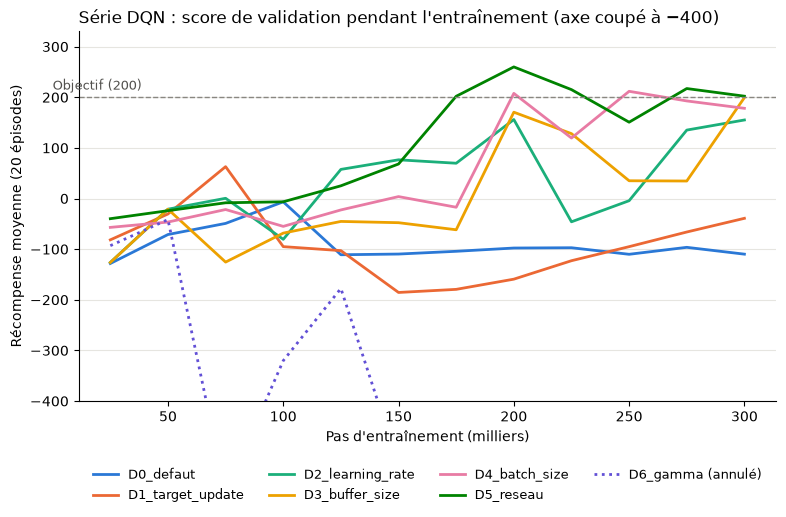

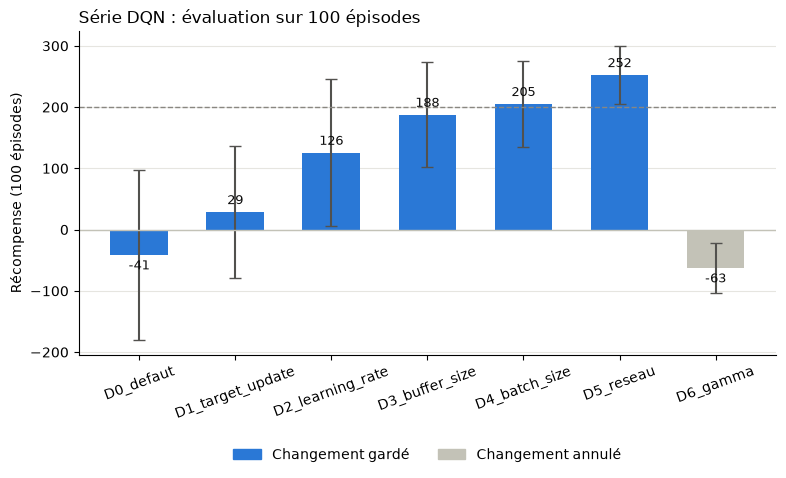

In [15]:
tracer_courbes(journal_dqn, "Série DQN : score de validation pendant l'entraînement")
tracer_barres(journal_dqn, "Série DQN : évaluation sur 100 épisodes")

#### Analyse de la série DQN

| Expérience | Changement | Moyenne ± écart-type | Épisodes ≥ 200 | Durée | Décision |
|---|---|---|---|---|---|
| D0 | aucun (300 000 pas) | −41,4 ± 138,9 | 15 % | 905 pas | référence |
| D1 | `target_update_interval` = 250 | +28,7 ± 108,4 | 0 % | 828 pas | gardé |
| D2 | `learning_rate` = 6e-4 | +125,5 ± 119,5 | 36 % | 696 pas | gardé |
| D3 | `buffer_size` = 50 000 | +187,6 ± 85,4 | 61 % | 589 pas | gardé |
| D4 | `batch_size` = 128 | +205,1 ± 69,6 | 74 % | 546 pas | gardé |
| **D5** | **`net_arch` = [256, 256]** | **+252,4 ± 47,3** | **92 %** | **352 pas** | **gardé** |
| D6 | `gamma` = 0,999 | −62,7 ± 41,3 | 0 % | 994 pas | annulé |

**D0 — le budget seul.** Passer de 100 000 à 300 000 pas fait gagner environ 70 points (−112,9 → −41,4), mais l'agent reste très irrégulier (écart-type 139) et flotte encore la plupart du temps (905 pas par épisode).

**D1 — le réseau cible.** Recopier le réseau cible tous les 250 pas au lieu de 10 000 fait gagner encore 70 points. Les « bonnes réponses » dont l'agent apprend sont à jour : il apprend sur des cibles qui ont du sens. Il devient plus régulier mais aussi plus prudent : il ne s'écrase plus, sans finir ses atterrissages (0 % au-dessus de 200).

**D2 — la vitesse d'apprentissage.** C'est le plus gros gain de la série (+97 points). Avec un `learning_rate` six fois plus grand, l'agent a le temps, en 300 000 pas, de passer du vol stationnaire à de vrais atterrissages. Revers : il prend plus de risques, et son pire épisode tombe à −317.

**D3 — la mémoire.** Une mémoire de 50 000 transitions au lieu d'un million fait gagner 62 points et fait baisser l'écart-type (120 → 85). En 300 000 pas, une mémoire d'un million de places garde **tout**, y compris les mauvaises transitions des débuts. Une mémoire plus petite les oublie et l'agent apprend de son comportement récent, meilleur.

**D4 — la taille du lot.** Moyenner chaque mise à jour sur 128 transitions au lieu de 32 rend l'apprentissage plus stable : l'écart-type baisse encore (85 → 70) et la moyenne passe 200 pour la première fois.

**D5 — un réseau plus grand.** Le meilleur résultat : +252,4 avec un écart-type de 47 et **aucun crash** sur 100 épisodes (le pire épisode vaut +31). Les épisodes ne durent plus que 352 pas : l'agent descend et se pose franchement au lieu de brûler du carburant en vol stationnaire. Avec 256 neurones par couche, le réseau peut apprendre une conduite plus fine (doser les moteurs, se redresser au bon moment).

**D6 — `gamma` = 0,999, un échec instructif.** Le score s'effondre à −62,7 : l'agent retombe dans le vol stationnaire (994 pas par épisode). Avec `gamma` = 0,99, l'agent regarde en pratique une centaine de pas devant lui ; avec 0,999, environ mille. Ses valeurs Q deviennent bien plus grandes et plus bruitées, donc plus lentes à apprendre, et 300 000 pas ne suffisent plus. Le changement est annulé.

**Conclusion de la série DQN.** La configuration D5 dépasse l'objectif avec une marge confortable et un écart-type faible. Ce résultat ne vient que d'une seule graine d'entraînement : la section 2.5 vérifie qu'il se reproduit avec d'autres graines.

### 2.3 — Série PPO (1 000 000 de pas par expérience)

Le brief conseille de tester PPO. DQN apprend une **valeur** pour chaque action et choisit la meilleure ; PPO apprend directement une **politique**, c'est-à-dire la probabilité de choisir chaque action, et la corrige par petits pas prudents.

| Expérience | Paramètre changé | Défaut → essai | Pourquoi |
|---|---|---|---|
| P0 | aucun | — | Référence : PPO par défaut, 1 environnement |
| P1 | `n_steps` | 2048 → 1024 | Nombre de pas joués avant chaque mise à jour : des mises à jour deux fois plus fréquentes |
| P2 | `n_envs` | 1 → 16 | 16 modules joués en parallèle : chaque mise à jour voit des situations bien plus variées |
| P3 | `gamma` | 0,99 → 0,999 | Plus de poids aux récompenses lointaines, comme pour D6 |
| P4 | `ent_coef` | 0 → 0,01 | Un bonus qui pousse l'agent à ne pas se figer trop tôt sur une seule façon d'agir |

In [16]:
journal_ppo, config_ppo, nom_ppo = lancer_serie("PPO", SERIE_PPO, BUDGET_PPO)

[P0_defaut] déjà entraîné : résultat relu depuis resultats/P0_defaut.json
P0_defaut              | moyenne   169.7 +/- 110.4 | min   -48.2 | réussite  64% | durée  325 pas | 16.9 min
[P1_n_steps] déjà entraîné : résultat relu depuis resultats/P1_n_steps.json
P1_n_steps             | moyenne   183.2 +/-  92.2 | min   -58.0 | réussite  70% | durée  333 pas | 17.7 min
[P2_n_envs] déjà entraîné : résultat relu depuis resultats/P2_n_envs.json
P2_n_envs              | moyenne   247.2 +/-  43.0 | min     8.7 | réussite  95% | durée  344 pas | 15.0 min
[P3_gamma] déjà entraîné : résultat relu depuis resultats/P3_gamma.json
P3_gamma               | moyenne   282.7 +/-  19.3 | min   235.4 | réussite 100% | durée  219 pas | 10.7 min
[P4_ent_coef] déjà entraîné : résultat relu depuis resultats/P4_ent_coef.json
P4_ent_coef            | moyenne   275.7 +/-  24.0 | min   142.3 | réussite  99% | durée  250 pas | 12.0 min


In [17]:
tableau(journal_ppo)
print("\nMeilleure expérience PPO :", nom_ppo)
print("Configuration            :", config_ppo)

Expérience         | Changement                   | Moyenne | Écart-type | Réussite |  Durée | Décision
-----------------------------------------------------------------------------------------------------------
P0_defaut          | aucun                        |   169.7 |      110.4 |      64% |    325 | référence
P1_n_steps         | n_steps=1024                 |   183.2 |       92.2 |      70% |    333 | gardé
P2_n_envs          | n_envs=16                    |   247.2 |       43.0 |      95% |    344 | gardé
P3_gamma           | gamma=0.999                  |   282.7 |       19.3 |     100% |    219 | gardé
P4_ent_coef        | ent_coef=0.01                |   275.7 |       24.0 |      99% |    250 | annulé

Meilleure expérience PPO : P3_gamma
Configuration            : {'n_envs': 16, 'n_steps': 1024, 'gamma': 0.999}


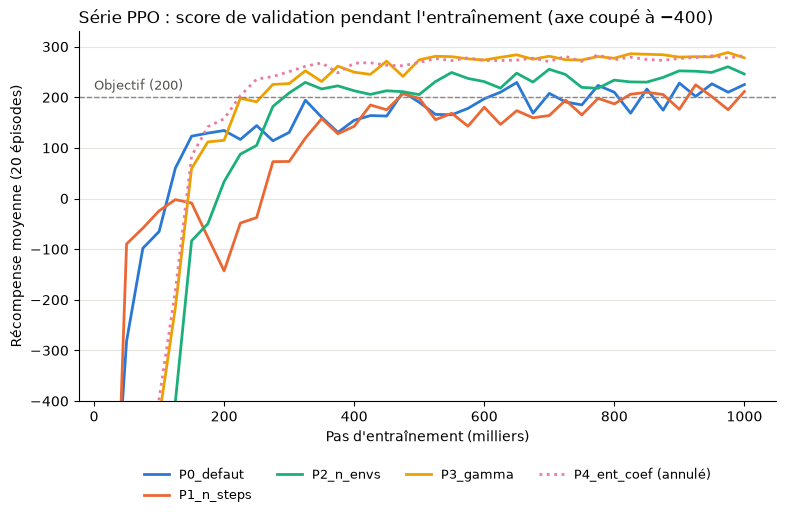

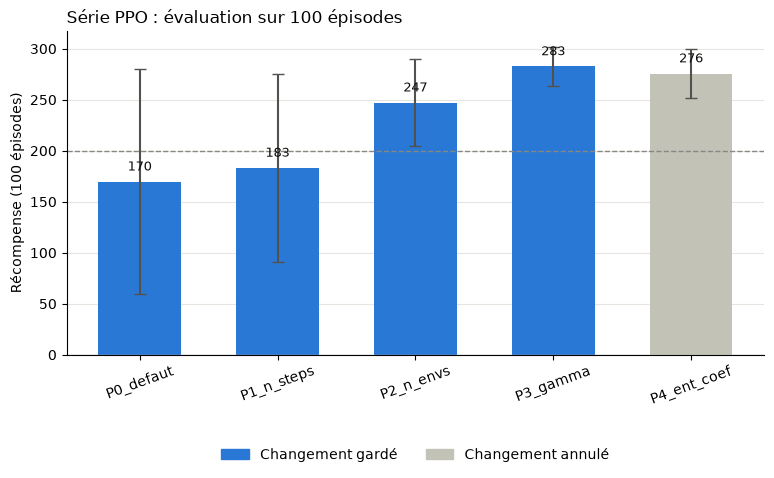

In [18]:
tracer_courbes(journal_ppo, "Série PPO : score de validation pendant l'entraînement")
tracer_barres(journal_ppo, "Série PPO : évaluation sur 100 épisodes")

#### Analyse de la série PPO

| Expérience | Changement | Moyenne ± écart-type | Épisodes ≥ 200 | Durée | Décision |
|---|---|---|---|---|---|
| P0 | aucun (PPO par défaut) | +169,7 ± 110,4 | 64 % | 325 pas | référence |
| P1 | `n_steps` = 1024 | +183,2 ± 92,2 | 70 % | 333 pas | gardé |
| P2 | `n_envs` = 16 | +247,2 ± 43,0 | 95 % | 344 pas | gardé |
| **P3** | **`gamma` = 0,999** | **+282,7 ± 19,3** | **100 %** | **219 pas** | **gardé** |
| P4 | `ent_coef` = 0,01 | +275,7 ± 24,0 | 99 % | 250 pas | annulé |

**P0 — PPO par défaut.** Sans aucun réglage, PPO fait déjà mieux que tous les DQN jusqu'à D3 : +169,7, avec 64 % d'atterrissages au-dessus de 200. Surtout, ses épisodes ne durent que 325 pas : contrairement au DQN par défaut, il a appris à **se poser**, pas seulement à flotter. Il a aussi eu plus de pas (1 000 000 contre 300 000), ce qui fait partie de la différence.

**P1 — des mises à jour plus fréquentes.** Avec `n_steps` = 1024, PPO corrige sa politique deux fois plus souvent. Le gain est modeste (+13,5) mais l'écart-type baisse (110 → 92).

**P2 — 16 environnements en parallèle.** Le plus gros gain de la série (+64). Chaque mise à jour s'appuie sur 16 modules partis de situations différentes au lieu d'un seul : la politique apprise est plus générale et l'écart-type est divisé par deux (92 → 43).

**P3 — `gamma` = 0,999.** Le meilleur résultat de toute l'étape : +282,7 avec un écart-type de 19 seulement, **100 % des épisodes au-dessus de 200** et un pire épisode à +235. Les épisodes tombent à 219 pas : l'agent se pose vite et économise son carburant.

Ce même changement avait fait échouer DQN (D6). La différence vient de la façon dont chaque algorithme apprend. DQN apprend ses valeurs Q en s'appuyant sur ses **propres estimations** de l'étape suivante : avec un horizon de mille pas, ses erreurs s'accumulent. PPO mesure ce qu'une action rapporte sur les **pas réellement joués**, en limitant le bruit grâce au lissage `gae_lambda`. Il profite donc de l'horizon long pour mieux valoriser l'atterrissage final.

**P4 — le bonus d'exploration.** `ent_coef` = 0,01 donne +275,7 ± 24,0 : un peu moins bien que P3, le changement est annulé. Avec 16 environnements variés, l'agent explore déjà assez ; le pousser à rester plus aléatoire n'aide pas.

**Conclusion de la série PPO.** La configuration P3 dépasse largement l'objectif, avec un écart-type très faible. Comme pour DQN, la section 2.5 vérifie qu'elle se reproduit avec d'autres graines.

### 2.4 — Robustesse : les meilleures configurations avec trois graines d'entraînement

Un seul entraînement peut avoir eu de la chance. On réentraîne donc les deux meilleures configurations (D5 pour DQN, P3 pour PPO) avec deux autres graines d'entraînement (1 et 2). Les graines d'évaluation ne changent pas : les trois modèles sont notés sur les mêmes 100 épisodes.

In [19]:
from entrainement import ALGOS

GRAINES = (0, 1, 2)


def noms_graines(nom):
    """Nom de l'expérience pour chaque graine : la graine 0 est l'expérience d'origine."""
    return [nom if s == 0 else f"{nom}_seed{s}" for s in GRAINES]


resultats = charger_resultats()
for nom in (nom_dqn, nom_ppo):
    r = resultats[nom]
    for nom_graine, s in zip(noms_graines(nom)[1:], GRAINES[1:]):
        lancer_experience(nom_graine, r["algo"], r["parametres"], r["total_timesteps"], n_envs=r["n_envs"], seed=s)
resultats = charger_resultats()

print(f"{'Configuration':<14} | {'Graine':>6} | {'Moyenne':>7} | {'Écart-type':>10} | {'Minimum':>7} | {'Réussite':>8}")
print("-" * 70)
synthese = {}
for nom in (nom_dqn, nom_ppo):
    moyennes = []
    for nom_graine, s in zip(noms_graines(nom), GRAINES):
        e = resultats[nom_graine]["evaluation"]
        moyennes.append(e["moyenne"])
        print(f"{nom:<14} | {s:>6} | {e['moyenne']:>7.1f} | {e['ecart_type']:>10.1f} | {e['minimum']:>7.1f} | {e['taux_reussite']:>8.0%}")
    synthese[nom] = np.mean(moyennes)
    print(f"{nom:<14} | {'moy.':>6} | {np.mean(moyennes):>7.1f} | (écart entre graines : {np.std(moyennes):.1f})")
    print("-" * 70)

[D5_reseau_seed1] déjà entraîné : résultat relu depuis resultats/D5_reseau_seed1.json


[D5_reseau_seed2] déjà entraîné : résultat relu depuis resultats/D5_reseau_seed2.json
[P3_gamma_seed1] déjà entraîné : résultat relu depuis resultats/P3_gamma_seed1.json
[P3_gamma_seed2] déjà entraîné : résultat relu depuis resultats/P3_gamma_seed2.json
Configuration  | Graine | Moyenne | Écart-type | Minimum | Réussite
----------------------------------------------------------------------
D5_reseau      |      0 |   252.4 |       47.3 |    30.9 |      92%
D5_reseau      |      1 |   245.4 |       41.4 |    -9.5 |      96%
D5_reseau      |      2 |   225.5 |       75.3 |   -76.3 |      80%
D5_reseau      |   moy. |   241.1 | (écart entre graines : 11.4)
----------------------------------------------------------------------
P3_gamma       |      0 |   282.7 |       19.3 |   235.4 |     100%
P3_gamma       |      1 |   283.6 |       19.1 |   237.3 |     100%
P3_gamma       |      2 |   278.5 |       21.0 |   225.6 |     100%
P3_gamma       |   moy. |   281.6 | (écart entre graines : 2.2

#### Analyse de la robustesse

| Configuration | Graine 0 | Graine 1 | Graine 2 | Moyenne des 3 | Écart entre graines |
|---|---|---|---|---|---|
| DQN D5 | 252,4 ± 47,3 | 245,4 ± 41,4 | 225,5 ± 75,3 | 241,1 | 11,4 |
| **PPO P3** | **282,7 ± 19,3** | **283,6 ± 19,1** | **278,5 ± 21,0** | **281,6** | **2,2** |

**Les deux configurations dépassent 200 avec chacune de leurs trois graines** : aucun des deux résultats n'était un coup de chance.

**PPO P3 est nettement meilleur et plus fiable.**
- Sa moyenne est plus haute d'environ 40 points.
- D'un épisode à l'autre, son écart-type est 2 à 4 fois plus faible (19 à 21 contre 41 à 75).
- D'un entraînement à l'autre, ses résultats ne varient que de 2 points, contre 11 pour DQN. Avec la graine 2, DQN descend à 225,5 avec des crashs (minimum −76), alors que PPO garde 100 % d'atterrissages réussis avec ses trois graines.

**À budget égal, DQN reste intéressant** : il atteint 241 en seulement 300 000 pas, contre 1 000 000 pour PPO, ce qui en fait l'algorithme le plus économe en expérience. Mais la mission demande une moyenne **stable** au-dessus de 200 : on retient **PPO P3**.

### 2.5 — Évaluation finale sur les épisodes de test

On retient la configuration dont la moyenne sur les trois graines est la meilleure, puis, parmi ses trois modèles, celui qui a le meilleur score de validation. Ce modèle est évalué **une seule fois** sur 100 épisodes de test (graines 5000 à 5099), jamais utilisés jusqu'ici : c'est la mesure honnête de ce que vaut l'agent sur des situations nouvelles.

In [20]:
nom_config = max(synthese, key=synthese.get)
nom_final = max(noms_graines(nom_config), key=lambda n: resultats[n]["evaluation"]["moyenne"])
algo_final = resultats[nom_final]["algo"]
print("Configuration retenue :", nom_config, f"(moyenne sur 3 graines : {synthese[nom_config]:.1f})")
print("Modèle retenu         :", nom_final, "-", algo_final)

modele_final = ALGOS[algo_final].load(Path("models") / nom_final / "best_model")
rec_test, durees_test = evaluer(modele_final, n_episodes=100, seed=SEED_TEST)
test = resume(rec_test, durees_test)

print(f"\nTest sur 100 épisodes jamais vus")
print(f"  Récompense moyenne : {test['moyenne']:.1f} +/- {test['ecart_type']:.1f}")
print(f"  Minimum            : {test['minimum']:.1f}")
print(f"  Épisodes >= 200    : {test['taux_reussite']:.0%}")
print(f"  Durée moyenne      : {test['duree_moyenne']:.0f} pas")
print(f"  Objectif atteint   : {'oui' if test['moyenne'] >= 200 else 'non'}")

Configuration retenue : P3_gamma (moyenne sur 3 graines : 281.6)
Modèle retenu         : P3_gamma_seed1 - PPO



Test sur 100 épisodes jamais vus
  Récompense moyenne : 282.4 +/- 18.3
  Minimum            : 230.1
  Épisodes >= 200    : 100%
  Durée moyenne      : 208 pas
  Objectif atteint   : oui


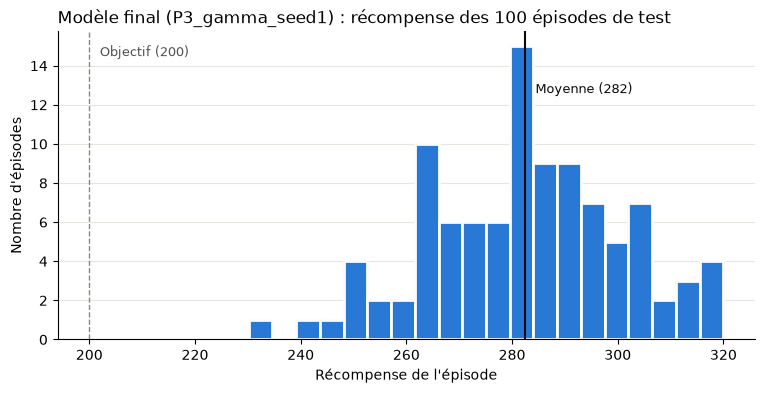

In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(rec_test, bins=20, color="#2a78d6", edgecolor="#fcfcfb", linewidth=2)
ax.axvline(200, color="#898781", linewidth=1, linestyle="--")
ax.text(202, ax.get_ylim()[1] * 0.92, "Objectif (200)", color="#52514e", fontsize=9)
ax.axvline(test["moyenne"], color="#0b0b0b", linewidth=1.5)
ax.text(test["moyenne"] + 2, ax.get_ylim()[1] * 0.80, f"Moyenne ({test['moyenne']:.0f})", color="#0b0b0b", fontsize=9)
ax.set_title(f"Modèle final ({nom_final}) : récompense des 100 épisodes de test", loc="left")
ax.set_xlabel("Récompense de l'épisode")
ax.set_ylabel("Nombre d'épisodes")
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [22]:
# Copie du modèle retenu sous un nom fixe : c'est ce fichier que l'API chargera
import json

shutil.copy(Path("models") / nom_final / "best_model.zip", Path("models") / "eagle1_final.zip")
# L'algorithme est noté à côté : pour recharger un modèle, il faut savoir si c'est un DQN ou un PPO
fiche = {"algo": algo_final, "experience": nom_final, "test": test}
Path("models/eagle1_final.json").write_text(json.dumps(fiche, indent=2, ensure_ascii=False), encoding="utf-8")
print("Modèle final sauvegardé : models/eagle1_final.zip (+ eagle1_final.json)")

Modèle final sauvegardé : models/eagle1_final.zip (+ eagle1_final.json)


### 2.6 — Conclusion de l'étape 2

**Objectif atteint.** Sur 100 épisodes de test jamais vus, le modèle final obtient **282,4 ± 18,3**, avec **100 % des épisodes au-dessus de 200** (le pire vaut 230,1). Le score de test est le même que celui de validation (283,6) : l'agent **généralise** à des situations nouvelles, il n'a pas sur-appris les épisodes qui ont servi à le choisir.

| | Étape 1 (DQN par défaut) | Étape 2 (PPO P3) |
|---|---|---|
| Récompense moyenne | −112,9 ± 74,5 | **282,4 ± 18,3** |
| Épisodes ≥ 200 | 2 % | **100 %** |
| Durée moyenne d'un épisode | 970 pas | **208 pas** |

La durée des épisodes résume le progrès : l'agent de l'étape 1 flottait jusqu'à la limite de 1000 pas en brûlant du carburant ; l'agent final se pose en un peu plus de 200 pas, ce qui répond aussi à l'objectif d'économie de carburant du brief.

**Configuration retenue** : PPO, `MlpPolicy`, 16 environnements en parallèle, `n_steps` = 1024, `gamma` = 0,999, autres paramètres par défaut, 1 000 000 de pas d'entraînement.

**Ce qu'on retient des expériences**
- Les réglages par défaut de DQN ne conviennent pas à LunarLander : il a fallu en changer cinq pour dépasser 200.
- Un même paramètre peut avoir des effets opposés selon l'algorithme : `gamma` = 0,999 fait échouer DQN mais donne à PPO son meilleur résultat.
- Le plus gros gain de PPO vient des environnements en parallèle, qui variaient les situations vues à chaque mise à jour.
- Vérifier sur plusieurs graines est indispensable : sur une seule graine, DQN D5 (252) et PPO P2 (247) semblaient équivalents, alors que les trois graines montrent PPO P3 bien plus stable.

Le modèle est sauvegardé dans `models/eagle1_final.zip`, avec une fiche `models/eagle1_final.json` qui indique son algorithme et son score de test : c'est lui que l'API chargera.

## Étape 3 — Déployer l'agent : API, GUI et tableau de bord

L'agent de l'étape 2 sait poser le module, mais il ne vit que dans ce notebook. L'étape 3 le rend **utilisable** :

- une **API** (FastAPI) qui reçoit un état et renvoie l'action de l'agent, joue des parties complètes et les enregistre ;
- un **GUI** (Streamlit) qui montre une partie jouée par l'agent : la vidéo de l'atterrissage et ce qu'il a décidé à chaque pas ;
- un **tableau de bord** (Streamlit) qui suit les performances de l'agent sur toutes les parties jouées.

**Prérequis remplis à l'étape 2** : récompense moyenne de **282,4 ± 18,3** sur 100 épisodes de test (objectif > 200), modèle sauvegardé dans `models/eagle1_final.zip` avec sa fiche `models/eagle1_final.json`.

### 3.1 — Architecture

**Le principe : toute la logique RL est dans l'API, le GUI ne fait qu'afficher.** Le GUI ne charge jamais le modèle et ne lance jamais l'environnement : il envoie des requêtes HTTP à l'API et affiche ses réponses. On pourrait remplacer Streamlit par une autre interface (web, mobile, Looker Studio) sans toucher à une ligne de RL.

```
 Navigateur
     │
     ▼
 GUI Streamlit (gui/)  ──── HTTP / JSON ────►  API FastAPI (api/)
   affiche                                       ├─ charge le modèle PPO (models/eagle1_final.zip)
   ne calcule rien                               ├─ joue les parties dans LunarLander-v3
                                                 ├─ enregistre chaque partie et chaque pas (SQLite)
                                                 ├─ filme les atterrissages (MP4)
                                                 └─ calcule les statistiques
```

**Organisation du code** : un dossier par couche, un rôle par fichier.

```
Astro/
├── config.py                 configuration (.env) et logs (loguru), partagés par l'API et le GUI
├── api/
│   ├── main.py               crée l'application, charge le modèle au démarrage, branche les routes
│   ├── dependencies.py       ce que FastAPI injecte dans les routes : agent, session de base, dossier vidéos
│   ├── routes/               les endpoints : reçoivent la requête, appellent les services, renvoient la réponse
│   ├── schemas/              les formats d'entrée et de sortie (Pydantic) : validation et documentation
│   ├── services/             la logique métier
│   │   ├── agent.py          charge le modèle et choisit une action pour un état
│   │   ├── simulation.py     joue une partie complète dans l'environnement
│   │   ├── regles.py         lit une partie : phase de vol, issue, carburant, réussite
│   │   └── video.py          enregistre la vidéo d'une partie
│   ├── repositories/         les requêtes à la base (SQLAlchemy) : enregistrer, lister, statistiques
│   └── db/                   le moteur, la session et les tables (partie, pas)
├── gui/
│   ├── app.py                point d'entrée : navigation entre les pages, état de l'API
│   ├── client.py             le SEUL fichier du GUI qui appelle l'API
│   ├── graphiques.py         transforme les réponses JSON en graphiques Altair
│   └── pages/
│       ├── partie.py         le GUI : une partie jouée
│       └── tableau_de_bord.py  le tableau de bord des performances
├── tests/                    les tests de l'API (pytest)
└── data/                     créé au premier lancement : parties.db et videos/
```

Pourquoi ce découpage : chaque couche ne connaît que celle du dessous. Une route ne fait pas de SQL, un service ne sait pas qu'il est appelé en HTTP, une page du GUI ne connaît pas les URL de l'API. Quand une partie change (nouvelle base, nouvel algorithme, nouvelle interface), on modifie un seul dossier.

### 3.2 — Instructions d'utilisation

**1. Installer** (une seule fois, depuis le dossier `Astro`) :

```powershell
uv venv .venv --python 3.12
.venv\Scripts\Activate.ps1
uv pip install -r requirements.txt
```

Si PowerShell refuse `Activate.ps1` (« l'exécution de scripts est désactivée »), autoriser les scripts locaux une fois pour son compte : `Set-ExecutionPolicy -Scope CurrentUser RemoteSigned`.

**2. Configurer** (facultatif) : toutes les valeurs ont une valeur par défaut dans `config.py`. Pour en changer une, copier `.env.example` en `.env` et modifier la ligne voulue :

| Variable | Défaut | Rôle |
|---|---|---|
| `MODEL_PATH` | `models/eagle1_final.zip` | modèle chargé par l'API |
| `DATABASE_PATH` | `data/parties.db` | base SQLite des parties jouées |
| `VIDEOS_PATH` | `data/videos` | une vidéo MP4 par partie jouée avec `/episodes` |
| `MAX_EPISODES_EVALUATE` | `200` | nombre maximal de parties par appel à `/evaluate` |
| `API_URL` | `http://127.0.0.1:8000` | adresse de l'API utilisée par le GUI |

**3. Lancer** : deux terminaux, chacun dans `Astro` avec le venv activé (le préfixe `(.venv)` doit apparaître).

| Terminal | Commande | Adresse |
|---|---|---|
| 1 — l'API | `uvicorn api.main:app --reload` | http://127.0.0.1:8000/docs (documentation interactive) |
| 2 — le GUI | `streamlit run gui/app.py` | http://localhost:8501 |

L'API doit tourner pour que le GUI fonctionne. Si elle est arrêtée, le GUI l'indique dans sa barre latérale (« L'API ne répond pas ») au lieu de planter.

**4. Tester l'API** : `pytest` depuis `Astro`. Les tests utilisent une base et un dossier vidéos temporaires : ils ne touchent pas à `data/`.

**Erreurs fréquentes**

| Message | Cause | Solution |
|---|---|---|
| `streamlit` (ou `uvicorn`) n'est pas reconnu | le venv n'est pas activé dans ce terminal | `.venv\Scripts\Activate.ps1`, ou `.venv\Scripts\python -m streamlit run gui/app.py` |
| `File does not exist: gui/app.py` | la commande est lancée depuis `Train_RL-` | se placer dans `Astro` |
| « L'API ne répond pas » dans le GUI | l'API n'est pas lancée | lancer le terminal 1 |
| `/health` renvoie `dégradé`, les routes répondent 503 | `models/eagle1_final.zip` est introuvable | réexécuter la cellule de sauvegarde de l'étape 2.5, ou corriger `MODEL_PATH` |

### 3.3 — L'API

L'API est documentée automatiquement par FastAPI : sur http://127.0.0.1:8000/docs, chaque endpoint affiche ses paramètres, un exemple et un bouton *Try it out* pour l'appeler depuis le navigateur.

| Méthode | Endpoint | Rôle |
|---|---|---|
| `POST` | `/play` | **reçoit un état (8 valeurs), renvoie l'action de l'agent** et la probabilité de chaque action |
| `POST` | `/episodes` | joue une partie complète **avec vidéo** et l'enregistre (utilisé par le GUI) |
| `GET` | `/episodes` | liste les parties, les plus récentes d'abord, par pages (`limite`, `decalage`, filtre `lot`) |
| `GET` | `/episodes/{id}` | détail pas à pas d'une partie : état, action, récompense, carburant, phase de vol |
| `GET` | `/episodes/{id}/video` | la vidéo MP4 de l'atterrissage |
| `POST` | `/evaluate` | joue N parties **sans vidéo** (200 au maximum), les enregistre comme un « lot » et renvoie leurs statistiques |
| `GET` | `/stats` | statistiques de toutes les parties ou d'un lot : moyenne, écart-type, réussite, carburant, issues, décisions par phase de vol |
| `GET` | `/health` | l'API tourne-t-elle, le modèle est-il chargé ? |
| `GET` | `/model` | algorithme, version et score de test du modèle |

**L'endpoint `/play`** est le cœur de la consigne : un état entre, une action sort.

```
POST /play
{"etat": [0.0, 1.4, 0.0, -0.1, 0.0, 0.0, 0.0, 0.0]}
```

Les 8 valeurs sont, dans l'ordre : position `x`, altitude `y`, vitesses `vx` et `vy`, `angle`, vitesse angulaire, pied gauche au sol, pied droit au sol. La réponse donne l'action choisie, son nom et les probabilités de la politique PPO :

```
{"action": 0, "nom_action": "rien", "probabilites": [0.80, 0.04, 0.00, 0.16]}
```

Cet état est celui du départ : le module est tout en haut et descend lentement. L'agent choisit de **ne rien faire** (80 %) : il laisse le module tomber et gardera le moteur principal pour freiner plus bas, ce qui économise du carburant. L'API joue toujours l'action la plus probable, comme `deterministic=True` à l'étape 2.

L'état est **validé avant d'atteindre le modèle** : une liste qui n'a pas 8 valeurs, une valeur `NaN` ou une valeur hors des bornes de LunarLander est refusée avec une erreur 422 qui nomme la valeur fautive. Un réseau de neurones répondrait sinon n'importe quoi sans prévenir.

**Comment une partie est jouée et lue.** `services/simulation.py` joue la partie pas à pas, comme l'évaluation de l'étape 2 (politique déterministe, une graine par partie : la même graine rejoue exactement la même partie). `services/regles.py` interprète ensuite chaque pas, sans rien décider :

- **la phase de vol** : *au sol* si un pied touche, *près du sol* sous une altitude de 0,3, *approche* sous 0,8, *haute altitude* au-dessus ;
- **l'issue** de la partie, avec les mêmes tests que LunarLander : *posé*, *crash*, *sorti de l'écran* ou *temps écoulé* ;
- **le carburant** : LunarLander n'a pas de réservoir, mais retire 0,30 point par pas de moteur principal et 0,03 par pas de moteur latéral ; on compte donc 1 unité pour le principal et 0,1 pour un latéral ;
- **la réussite** : une partie est réussie à partir de 200 points, le même seuil qu'à l'étape 2.

Chaque partie et chacun de ses pas sont enregistrés dans une base SQLite (SQLAlchemy). C'est ce qui permet au tableau de bord de calculer des statistiques sur toutes les parties jouées, et de compter les **décisions de l'agent selon la phase de vol** directement en SQL.

### 3.4 — Le GUI : regarder une partie jouée

Page **« Partie jouée »** du GUI Streamlit :

- **Lancer l'atterrissage** : le GUI demande une partie à l'API (`POST /episodes`). On peut donner une graine pour rejouer une situation de départ précise, ou la laisser vide pour une situation au hasard.
- **Revoir une partie** : une liste des parties déjà jouées avec vidéo, les plus récentes d'abord.

Pour la partie choisie, la page affiche :

| Élément | Ce qu'il montre |
|---|---|
| Indicateurs | récompense, issue (réussie ou ratée), durée en pas, carburant consommé |
| **Vidéo** | l'atterrissage filmé par l'API |
| Décisions de la partie | pour chaque phase de vol, la part de chaque action |
| Altitude et phase de vol | la descente du module, chaque point coloré par la phase reconnue par l'API |
| Score cumulé | comment la récompense s'accumule, avec la ligne de l'objectif à 200 |
| Action choisie à chaque pas | la suite des décisions de l'agent, du début à la fin de la partie |
| Tableau pas à pas | toutes les données brutes, repliable |

Tous les graphiques ont une info-bulle au survol. Une partie enregistrée ne change plus : sa vidéo et son détail sont gardés en cache (20 parties au maximum, pour limiter la mémoire).

### 3.5 — Le tableau de bord : suivre les performances

Page **« Tableau de bord »** :

- **Lancer une évaluation** : fait jouer N parties à l'API (`POST /evaluate`, jusqu'à 200) pour remplir la base, avec une graine de départ facultative.
- **Parties analysées** : toutes les parties enregistrées, ou une seule évaluation (un « lot »).

| Élément | Ce qu'il montre |
|---|---|
| Indicateurs | nombre de parties, **récompense moyenne** (avec l'écart au score de test de l'étape 2), **écart-type**, taux de réussite, carburant moyen, durée moyenne |
| Récompense par partie | chaque partie (point coloré par son issue), la **moyenne glissante** et une bande de **± 1 écart-type** ; la taille de la fenêtre se règle avec un curseur |
| Répartition des récompenses | l'histogramme des scores, avec l'objectif à 200 |
| Issue des parties | combien de parties posées, crashées, sorties de l'écran ou arrêtées par la limite de temps |
| **Décisions selon la phase de vol** | pour chaque phase, la part de chaque action : la politique de l'agent selon la circonstance |

La heatmap des décisions répond à la question « que fait l'IA selon la situation ? ». Chaque ligne fait 100 %, pour comparer des phases qui ne durent pas le même nombre de pas. Sur les parties jouées pendant le développement, la politique est très lisible :

- en **haute altitude**, l'agent répartit ses actions entre les trois moteurs : il corrige sa position et son angle ;
- en **approche** et **près du sol**, il utilise surtout le **moteur principal** (environ deux pas sur trois) pour freiner la descente ;
- **au sol**, il coupe presque tout (« rien » dans environ 90 % des pas) : une fois posé, chaque allumage coûte des points.

Toutes ces statistiques sont calculées par l'API (`GET /stats`). Le tableau de bord ne calcule que la moyenne glissante de la courbe, qui sert seulement à l'affichage.

### 3.6 — Points de vigilance

**Toute la logique RL côté API.** Le GUI n'importe ni `gymnasium` ni `stable_baselines3` et ne charge jamais le modèle. Il passe par `gui/client.py`, seul fichier qui fait des appels HTTP. Les règles qui interprètent une partie (phase de vol, issue, carburant, réussite) sont aussi dans l'API, pour que tous les clients lisent les parties de la même façon.

**Mémoire (RAM).**

- `/evaluate` joue ses parties **sans vidéo** et est plafonné à 200 parties par appel (`MAX_EPISODES_EVALUATE`).
- `GET /episodes` est **paginé** (500 parties au maximum par page). Côté GUI, `client.toutes_les_parties()` est un **générateur** qui lit la base page par page au lieu de tout charger d'un coup.
- La vidéo est écrite sur le disque image par image pendant la partie, puis servie par morceaux : elle n'est jamais gardée entière en mémoire par l'API.
- Les caches du GUI sont limités (20 parties regardées, statistiques gardées 30 secondes).

**Robustesse.**

- Le modèle est chargé **une fois, au démarrage** de l'API, et non à chaque requête. S'il manque, l'API démarre quand même, `/health` le signale et les routes qui en ont besoin répondent 503 au lieu de planter.
- Les entrées sont validées par Pydantic avant d'atteindre le modèle (erreurs 422 explicites).
- Côté GUI, toute erreur réseau ou HTTP devient un message lisible affiché dans la page.

**Tests.** 24 tests `pytest` vérifient chaque endpoint (`tests/test_play.py`, `test_episodes.py`, `test_evaluation.py`, `test_statistiques.py`, `test_systeme.py`) sur une base temporaire, y compris les cas d'erreur : état invalide, partie introuvable, modèle absent.

### 3.7 — Conclusion de l'étape 3

| Résultat attendu | Réalisation |
|---|---|
| Prérequis : agent > 200 de moyenne | PPO, **282,4 ± 18,3** sur 100 épisodes de test, 100 % au-dessus de 200 |
| Prérequis : meilleur modèle sauvegardé | `models/eagle1_final.zip` et sa fiche `models/eagle1_final.json` |
| API fonctionnelle, endpoint `/play` (état → action) | API FastAPI, 9 endpoints documentés sur `/docs`, 24 tests qui passent |
| GUI affichant une partie jouée | page « Partie jouée » : vidéo de l'atterrissage et courbes pas à pas |
| Tableau de bord interactif | page « Tableau de bord » : courbe des récompenses, moyenne, écart-type, issues, décisions selon la phase de vol |
| Logique RL côté backend | le GUI ne fait que des appels HTTP via `gui/client.py` |
| Attention à la RAM | parties sans vidéo pour `/evaluate`, pagination, générateur, caches limités |
| Code et instructions documentés | docstrings et commentaires dans le code, cette étape 3 du notebook |

L'agent n'est plus seulement un fichier de poids entraîné dans un notebook. C'est un service : n'importe quel programme peut lui demander une action par HTTP, chaque partie jouée est enregistrée, et ses performances se suivent dans un tableau de bord.